In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import sys

PROJECT_DIR = "/content/drive/MyDrive/mini project train and test/swin_project"

os.chdir(PROJECT_DIR)

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

print("Project directory:")
print(os.getcwd())

print("\nFiles in project:")
for f in sorted(os.listdir(PROJECT_DIR)):
    print(" ", f)

Project directory:
/content/drive/MyDrive/mini project train and test/swin_project

Files in project:
  .DS_Store
  .ipynb_checkpoints
  __pycache__
  check_dataset.py
  checkpoints
  dataset.py
  dataset_B.py
  evaluate_test.py
  metadata.csv
  model.py
  model_B.py
  results
  resume_train.py
  train.py
  train_B.py


In [ ]:
import os

print("CHECKPOINTS")
print("=" * 50)

checkpoint_dir = os.path.join(PROJECT_DIR, "checkpoints")

for f in sorted(os.listdir(checkpoint_dir)):
    path = os.path.join(checkpoint_dir, f)
    if os.path.isfile(path):
        print(f"{f:35s} {os.path.getsize(path) / (1024**2):.2f} MB")

print("\nRESULTS")
print("=" * 50)

results_dir = os.path.join(PROJECT_DIR, "results")

for f in sorted(os.listdir(results_dir)):
    path = os.path.join(results_dir, f)
    if os.path.isfile(path):
        print(f"{f:35s} {os.path.getsize(path) / (1024**2):.2f} MB")

CHECKPOINTS
best_swin_A.pth                     315.48 MB
best_swin_B.pth                     110.78 MB
latest_swin_A.pth                   315.48 MB
latest_swin_B.pth                   110.78 MB
swin_A_best.pth                     315.47 MB

RESULTS
resume_train                        0.01 MB
swin_A_resume_metrics.csv           0.00 MB
test_classification_report.csv      0.00 MB
test_confusion_matrix.csv           0.00 MB
test_summary.json                   0.00 MB
training_metrics_B.csv              0.00 MB


In [ ]:
import pandas as pd
import json
import os

results_dir = os.path.join(PROJECT_DIR, "results")

# Classification report
report_path = os.path.join(results_dir, "test_classification_report.csv")
report = pd.read_csv(report_path)

print("=" * 70)
print("SWIN-A CLASSIFICATION REPORT")
print("=" * 70)
print(report.to_string(index=False))

# Confusion matrix
cm_path = os.path.join(results_dir, "test_confusion_matrix.csv")
cm = pd.read_csv(cm_path, index_col=0)

print("\n" + "=" * 70)
print("SWIN-A CONFUSION MATRIX")
print("=" * 70)
print(cm)

# Summary
summary_path = os.path.join(results_dir, "test_summary.json")

with open(summary_path, "r") as f:
    summary = json.load(f)

print("\n" + "=" * 70)
print("SWIN-A TEST SUMMARY")
print("=" * 70)

for key, value in summary.items():
    print(f"{key}: {value}")

SWIN-A CLASSIFICATION REPORT
              Unnamed: 0  precision   recall  f1-score   support
   bacterial_leaf_blight   0.979592 0.979592  0.979592   98.0000
   bacterial_leaf_streak   0.974359 1.000000  0.987013   76.0000
bacterial_panicle_blight   0.985507 1.000000  0.992701   68.0000
        black_stem_borer   0.973684 0.973684  0.973684   76.0000
                   blast   0.977208 0.971671  0.974432  353.0000
              brown_spot   0.994595 0.973545  0.983957  189.0000
            downy_mildew   0.962121 0.969466  0.965779  131.0000
                   hispa   0.990506 0.969040  0.979656  323.0000
             leaf_roller   0.982143 1.000000  0.990991  165.0000
                  normal   0.983516 0.991690  0.987586  361.0000
                  tungro   0.983165 0.996587  0.989831  293.0000
        white_stem_borer   0.989474 0.984293  0.986877  191.0000
       yellow_stem_borer   1.000000 1.000000  1.000000  115.0000
                accuracy   0.983600 0.983600  0.983600    0.9

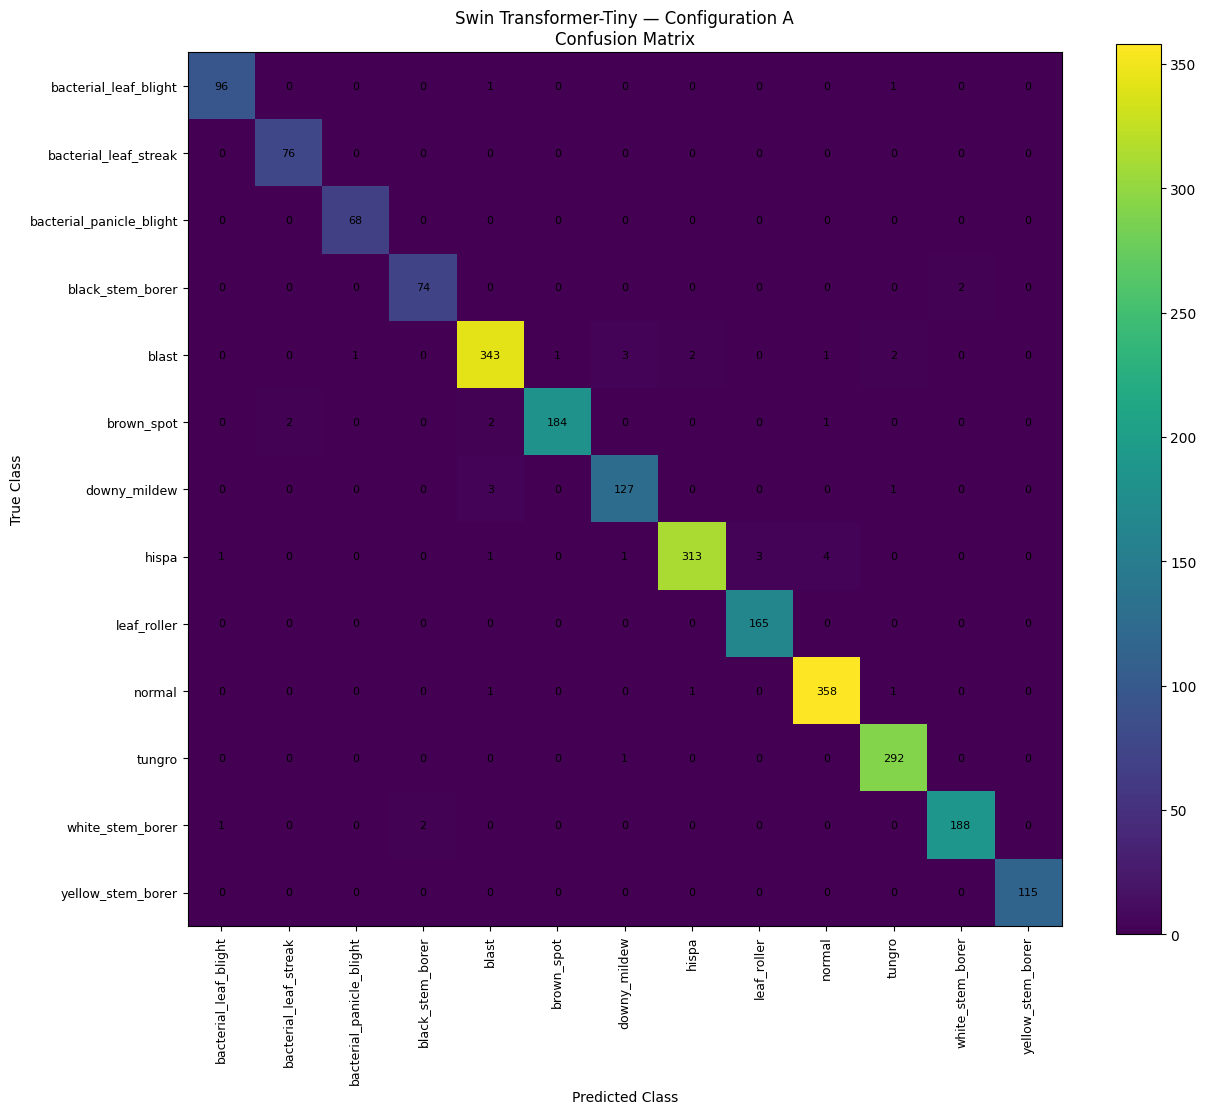

Saved:
/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Load saved confusion matrix
cm_path = os.path.join(PROJECT_DIR, "results", "test_confusion_matrix.csv")
cm = pd.read_csv(cm_path, index_col=0)

plt.figure(figsize=(13, 11))

plt.imshow(cm.values, interpolation="nearest")
plt.title("Swin Transformer-Tiny — Configuration A\nConfusion Matrix")
plt.colorbar()

classes = cm.index.tolist()

plt.xticks(
    range(len(classes)),
    classes,
    rotation=90,
    fontsize=9
)

plt.yticks(
    range(len(classes)),
    classes,
    fontsize=9
)

# Add numbers inside cells
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm.iloc[i, j]),
            ha="center",
            va="center",
            fontsize=8
        )

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

output_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_confusion_matrix.png"
)

plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:")
print(output_path)

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_confusion_matrix.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

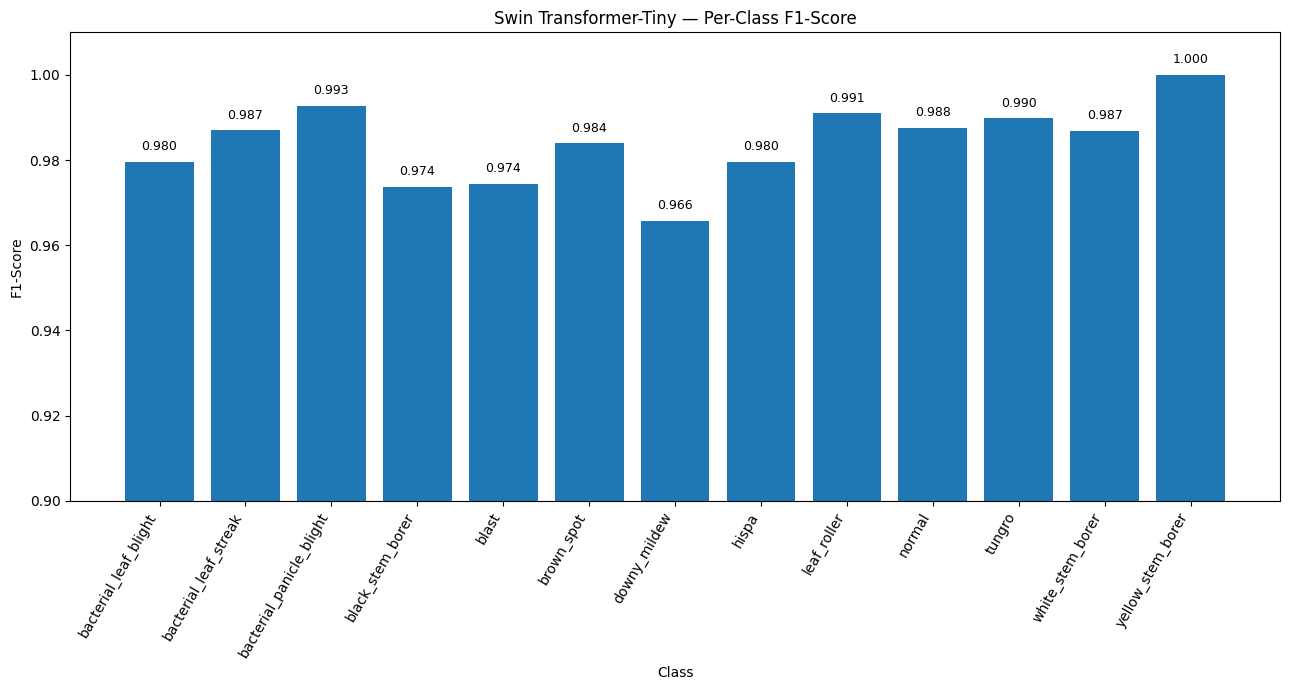

Saved:
/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_per_class_f1.png


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# Load classification report
report_path = os.path.join(
    PROJECT_DIR,
    "results",
    "test_classification_report.csv"
)

report = pd.read_csv(report_path)

# Keep only the 13 disease/health classes
class_rows = report[
    ~report["Unnamed: 0"].isin(
        ["accuracy", "macro avg", "weighted avg"]
    )
].copy()

classes = class_rows["Unnamed: 0"].tolist()
f1_scores = class_rows["f1-score"].tolist()

plt.figure(figsize=(13, 7))

plt.bar(classes, f1_scores)

plt.title("Swin Transformer-Tiny — Per-Class F1-Score")
plt.xlabel("Class")
plt.ylabel("F1-Score")
plt.ylim(0.90, 1.01)

plt.xticks(rotation=60, ha="right")

# Add F1 values above bars
for i, score in enumerate(f1_scores):
    plt.text(
        i,
        score + 0.002,
        f"{score:.3f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()

output_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_per_class_f1.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:")
print(output_path)

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_per_class_f1.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_resume_metrics.csv"
)

history = pd.read_csv(history_path)

print("Columns available:")
print(history.columns.tolist())

print("\nTraining history:")
print(history.to_string(index=False))

Columns available:
['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy', 'val_macro_f1', 'val_mcc', 'learning_rate', 'time_seconds']

Training history:
 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1  val_mcc  learning_rate  time_seconds
    11    0.151680        0.946624  0.098181      0.964390      0.960982 0.960549       0.000100    373.849376
    12    0.122292        0.956502  0.103226      0.965480      0.966628 0.961798       0.000100    386.753574
    13    0.123962        0.954599  0.075117      0.973837      0.974061 0.970943       0.000100    385.375208
    14    0.096370        0.964749  0.081808      0.969840      0.967523 0.966540       0.000100    387.485412
    15    0.128486        0.952968  0.067211      0.979288      0.977714 0.976997       0.000100    383.425199
    16    0.093710        0.964386  0.053176      0.985102      0.985394 0.983437       0.000100    383.885211
    17    0.085160        0.969189  0.080888      0.973

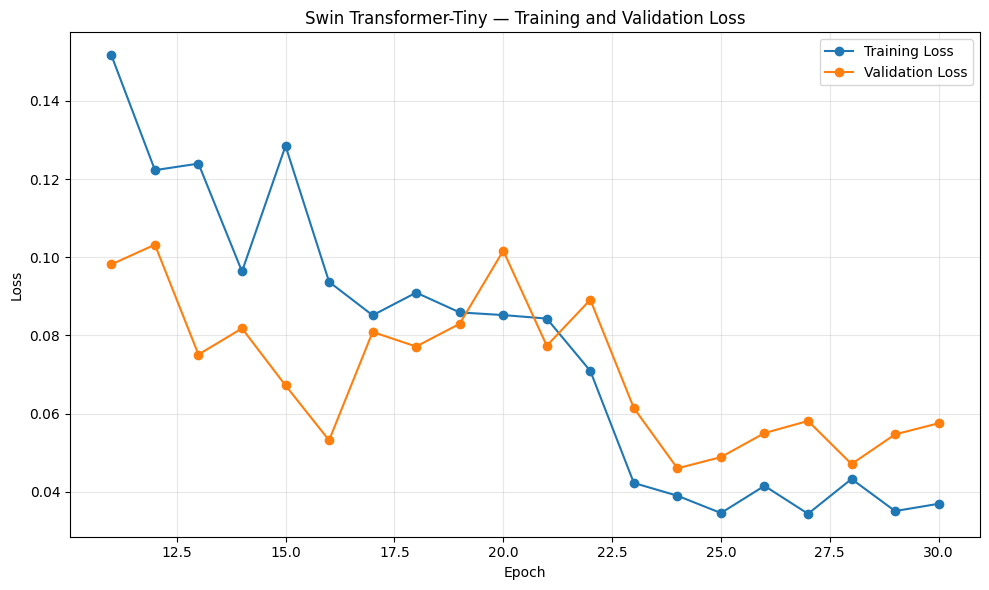

Saved: /content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_loss_curve.png


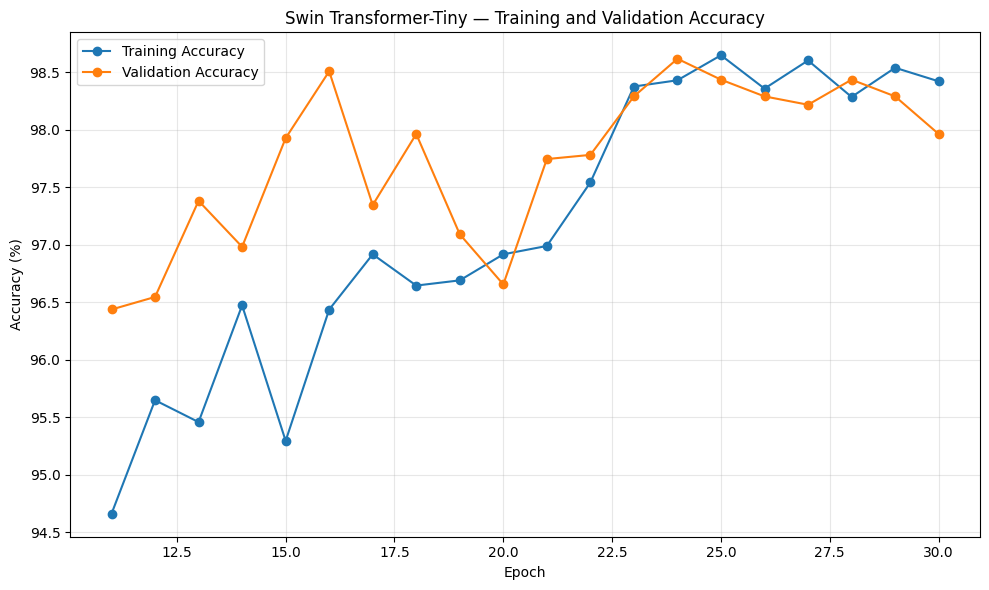

Saved: /content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_accuracy_curve.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_resume_metrics.csv"
)

history = pd.read_csv(history_path)

# -----------------------------
# 1. TRAINING vs VALIDATION LOSS
# -----------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history["epoch"],
    history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history["epoch"],
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Swin Transformer-Tiny — Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_loss_curve.png"
)

plt.savefig(loss_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", loss_path)


# -----------------------------
# 2. TRAINING vs VALIDATION ACCURACY
# -----------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    history["epoch"],
    history["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history["epoch"],
    history["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Swin Transformer-Tiny — Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_path = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_accuracy_curve.png"
)

plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", accuracy_path)

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_loss_curve.png"
)

files.download(
    "/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_accuracy_curve.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Device: cpu
Classes: ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'black_stem_borer', 'blast', 'brown_spot', 'downy_mildew', 'hispa', 'leaf_roller', 'normal', 'tungro', 'white_stem_borer', 'yellow_stem_borer']
Swin-A checkpoint loaded successfully.
Total test images found: 2439
Correct predictions: 98
Incorrect predictions: 2


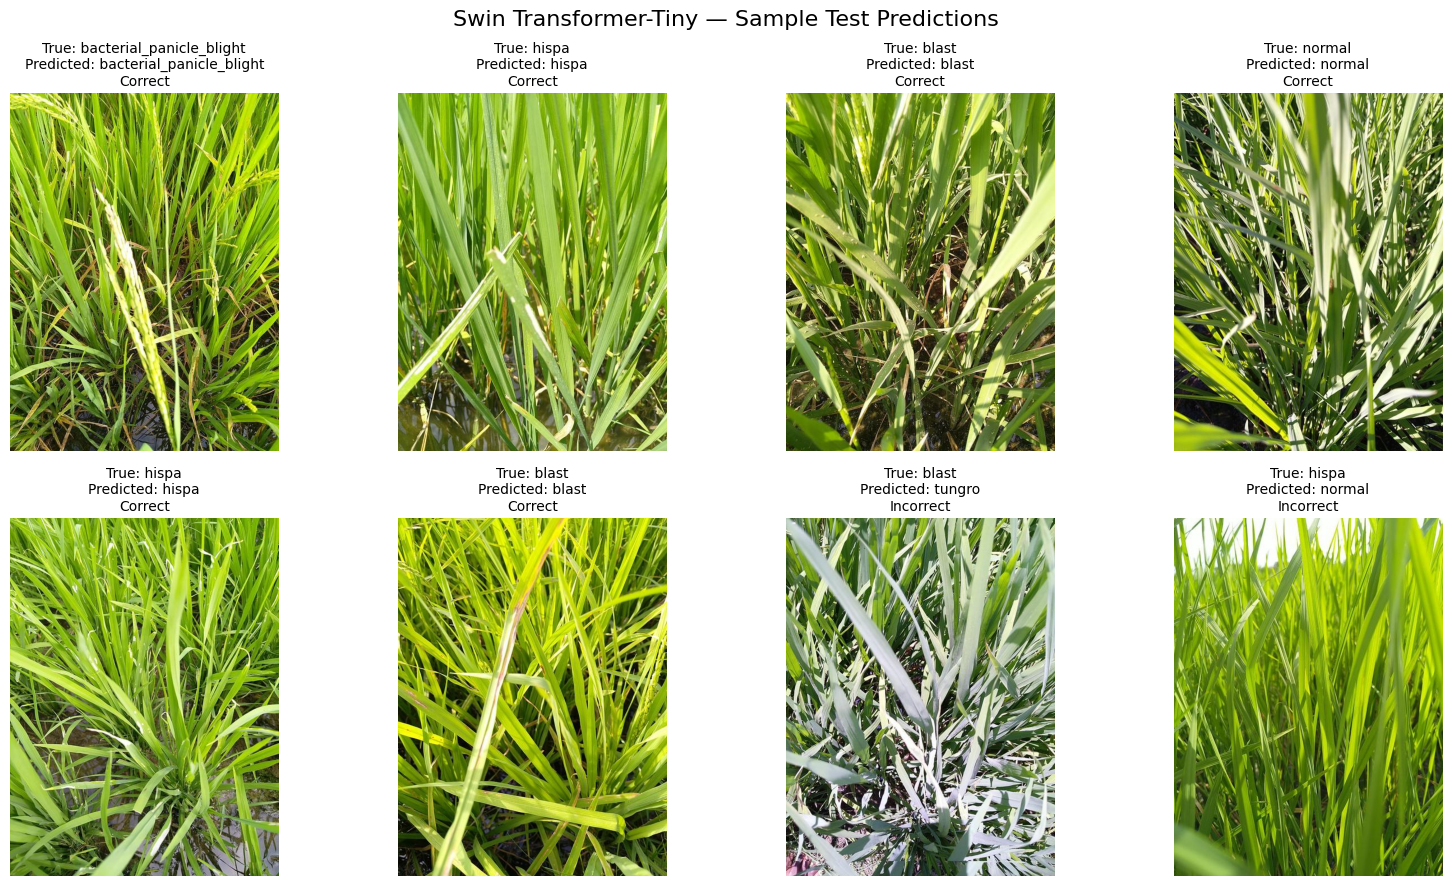


Saved:
/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_sample_predictions.png


In [ ]:
import os
import random
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from model import SwinTinyClassifier

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

TEST_DIR = "/content/drive/MyDrive/mini project train and test/test"
CHECKPOINT = os.path.join(
    PROJECT_DIR,
    "checkpoints",
    "best_swin_A.pth"
)

OUTPUT_PATH = os.path.join(
    PROJECT_DIR,
    "results",
    "swin_A_sample_predictions.png"
)

# Your 13 classes
CLASS_NAMES = sorted([
    d for d in os.listdir(TEST_DIR)
    if os.path.isdir(os.path.join(TEST_DIR, d))
])

print("Device:", DEVICE)
print("Classes:", CLASS_NAMES)

# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

model = SwinTinyClassifier(
    num_classes=len(CLASS_NAMES)
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

# Handle different checkpoint formats
if "model_state_dict" in checkpoint:
    model.load_state_dict(checkpoint["model_state_dict"])
elif "state_dict" in checkpoint:
    model.load_state_dict(checkpoint["state_dict"])
else:
    model.load_state_dict(checkpoint)

model = model.to(DEVICE)
model.eval()

print("Swin-A checkpoint loaded successfully.")

# --------------------------------------------------
# IMAGE TRANSFORM
# --------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# --------------------------------------------------
# COLLECT TEST IMAGES
# --------------------------------------------------

image_files = []

valid_extensions = (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")

for class_name in CLASS_NAMES:
    class_dir = os.path.join(TEST_DIR, class_name)

    for filename in os.listdir(class_dir):
        if filename.endswith(valid_extensions):
            image_files.append(
                (
                    os.path.join(class_dir, filename),
                    class_name
                )
            )

print("Total test images found:", len(image_files))

# --------------------------------------------------
# RUN PREDICTIONS
# --------------------------------------------------

random.seed(123)

# Start with random samples
random_samples = random.sample(
    image_files,
    min(100, len(image_files))
)

predictions = []

with torch.no_grad():

    for image_path, true_class in random_samples:

        image = Image.open(image_path).convert("RGB")
        input_tensor = transform(image).unsqueeze(0).to(DEVICE)

        output = model(input_tensor)
        predicted_index = torch.argmax(
            output,
            dim=1
        ).item()

        predicted_class = CLASS_NAMES[predicted_index]

        predictions.append(
            (
                image_path,
                true_class,
                predicted_class
            )
        )

# --------------------------------------------------
# SELECT CORRECT + INCORRECT EXAMPLES
# --------------------------------------------------

correct = [
    x for x in predictions
    if x[1] == x[2]
]

incorrect = [
    x for x in predictions
    if x[1] != x[2]
]

print("Correct predictions:", len(correct))
print("Incorrect predictions:", len(incorrect))

# Prefer 6 correct + 2 incorrect
selected = correct[:6] + incorrect[:2]

# If there aren't enough errors, fill with correct samples
if len(selected) < 8:
    selected = predictions[:8]

# --------------------------------------------------
# CREATE VISUAL
# --------------------------------------------------

fig, axes = plt.subplots(
    2,
    4,
    figsize=(16, 9)
)

axes = axes.flatten()

for ax, item in zip(axes, selected):

    image_path, true_class, predicted_class = item

    image = Image.open(image_path).convert("RGB")

    ax.imshow(image)
    ax.axis("off")

    if true_class == predicted_class:
        result = "Correct"
    else:
        result = "Incorrect"

    ax.set_title(
        f"True: {true_class}\n"
        f"Predicted: {predicted_class}\n"
        f"{result}",
        fontsize=10
    )

# Hide unused axes
for ax in axes[len(selected):]:
    ax.axis("off")

fig.suptitle(
    "Swin Transformer-Tiny — Sample Test Predictions",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    OUTPUT_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(OUTPUT_PATH)

In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_sample_predictions.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/mini project train and test"
PROJECT_DIR = os.path.join(BASE_DIR, "swin_project")
IMAGE_DIR = os.path.join(BASE_DIR, "test_images")
CHECKPOINT = os.path.join(PROJECT_DIR, "checkpoints", "best_swin_A.pth")

print("Images folder exists:", os.path.isdir(IMAGE_DIR))
print("Checkpoint exists:", os.path.isfile(CHECKPOINT))

images = [
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("Total images found:", len(images))
print("First five:", sorted(images)[:5])

Mounted at /content/drive
Images folder exists: True
Checkpoint exists: True
Total images found: 3469
First five: ['200001.jpg', '200002.jpg', '200003.jpg', '200004.jpg', '200005.jpg']


In [ ]:
import os
import sys
import torch
import pandas as pd
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Project paths
sys.path.insert(0, PROJECT_DIR)

TRAIN_DIR = os.path.join(BASE_DIR, "train")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Use the same alphabetical class order as the training folders
CLASS_NAMES = sorted([
    name for name in os.listdir(TRAIN_DIR)
    if os.path.isdir(os.path.join(TRAIN_DIR, name))
])

print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)

# Load your actual trained Swin-A architecture
from model import SwinTinyClassifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = SwinTinyClassifier(num_classes=len(CLASS_NAMES))

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
    weights_only=False
)

# Support common checkpoint formats
if "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

model.load_state_dict(state_dict)
model = model.to(DEVICE)
model.eval()

print("Model loaded successfully on:", DEVICE)

# Evaluation preprocessing — match the preprocessing used in training
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Collect the new images in filename order
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

results = []
errors = []

with torch.inference_mode():
    for i, filename in enumerate(image_files):
        path = os.path.join(IMAGE_DIR, filename)

        try:
            with Image.open(path) as img:
                image = transform(img.convert("RGB")).unsqueeze(0)

            image = image.to(DEVICE)
            logits = model(image)
            probabilities = torch.softmax(logits, dim=1)

            confidence, predicted_index = probabilities.max(dim=1)

            results.append({
                "image": filename,
                "predicted_class": CLASS_NAMES[predicted_index.item()],
                "confidence_percent": round(
                    confidence.item() * 100, 2
                )
            })

        except Exception as e:
            errors.append({
                "image": filename,
                "error": str(e)
            })

        if (i + 1) % 200 == 0 or (i + 1) == len(image_files):
            print(f"Processed {i + 1}/{len(image_files)} images")

# Save predictions separately from your original test results
output_csv = os.path.join(
    RESULTS_DIR, "swin_A_new_images_predictions.csv"
)

predictions = pd.DataFrame(results)
predictions.to_csv(output_csv, index=False)

if errors:
    pd.DataFrame(errors).to_csv(
        os.path.join(RESULTS_DIR, "swin_A_prediction_errors.csv"),
        index=False
    )

print("\nPREDICTION COMPLETE")
print("Successfully processed:", len(results))
print("Failed images:", len(errors))
print("Saved to:", output_csv)

display(predictions.head(15))

print("\nPredicted class counts:")
display(
    predictions["predicted_class"]
    .value_counts()
    .rename_axis("class")
    .reset_index(name="image_count")
)

Number of classes: 13
Classes: ['bacterial_leaf_blight', 'bacterial_leaf_streak', 'bacterial_panicle_blight', 'black_stem_borer', 'blast', 'brown_spot', 'downy_mildew', 'hispa', 'leaf_roller', 'normal', 'tungro', 'white_stem_borer', 'yellow_stem_borer']
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:01<00:00, 112MB/s] 


Model loaded successfully on: cuda
Processed 200/3469 images
Processed 400/3469 images
Processed 600/3469 images
Processed 800/3469 images
Processed 1000/3469 images
Processed 1200/3469 images
Processed 1400/3469 images
Processed 1600/3469 images
Processed 1800/3469 images
Processed 2000/3469 images
Processed 2200/3469 images
Processed 2400/3469 images
Processed 2600/3469 images
Processed 2800/3469 images
Processed 3000/3469 images
Processed 3200/3469 images
Processed 3400/3469 images
Processed 3469/3469 images

PREDICTION COMPLETE
Successfully processed: 3469
Failed images: 0
Saved to: /content/drive/MyDrive/mini project train and test/swin_project/results/swin_A_new_images_predictions.csv


,image,predicted_class,confidence_percent
0,200001.jpg,hispa,100.00
1,200002.jpg,normal,100.00
2,200003.jpg,blast,99.66
3,200004.jpg,blast,100.00
4,200005.jpg,blast,100.00
5,200006.jpg,brown_spot,99.67
6,200007.jpg,white_stem_borer,100.00
7,200008.jpg,brown_spot,100.00
8,200009.jpg,hispa,99.99
9,200010.jpg,normal,100.00



Predicted class counts:


,class,image_count
0,blast,577
1,normal,551
2,hispa,531
3,tungro,363
4,brown_spot,315
5,white_stem_borer,302
6,downy_mildew,206
7,bacterial_leaf_blight,168
8,bacterial_panicle_blight,142
9,bacterial_leaf_streak,128
